<a href="https://colab.research.google.com/github/leila-megdiche/Auspify-ML-Internship/blob/main/01_recommendation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The goal is to recommend Netflix titles similar to a movie or TV show that a user likes.

Load dataset

In [1]:
import pandas as pd

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Saving Dataset.csv to Dataset.csv
Dataset loaded successfully!
Dataset shape: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


Check the available columns

In [2]:
print("Columns in the dataset:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Columns in the dataset:
['show_id', 'type', 'title', 'director', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in']

Missing values:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64


In [3]:
print(df[["title", "listed_in"]].head())

                              title  \
0              Dick Johnson Is Dead   
1                         Ganglands   
2                     Midnight Mass   
3  Confessions of an Invisible Girl   
4                           Sankofa   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2                 TV Dramas, TV Horror, TV Mysteries  
3                 Children & Family Movies, Comedies  
4   Dramas, Independent Movies, International Movies  


Prepare the data

In [4]:
# Keep only rows with a title and genre information
df = df.dropna(subset=["title", "listed_in"]).copy()

# Make sure titles are treated as text
df["title"] = df["title"].astype(str)

# Prepare the genre information
df["listed_in"] = df["listed_in"].str.lower()

print("Data prepared!")
print("Number of titles:", len(df))

Data prepared!
Number of titles: 8790


Build the recommendation system

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [6]:
# Convert genres into numerical features
tfidf = TfidfVectorizer(token_pattern=r"(?u)\b\w+\b")

genre_matrix = tfidf.fit_transform(df["listed_in"])

# Calculate similarity between titles
similarity = cosine_similarity(genre_matrix)

print("Recommendation model created successfully!")

Recommendation model created successfully!


In [7]:
#Recommend similar Netflix titles

def recommend(title, number=5):

    # Find the title
    matches = df[df["title"].str.lower() == title.lower()]

    if matches.empty:
        print("Title not found in the dataset.")
        return

    # Get the index of the first matching title
    index = matches.index[0]

    # Find the corresponding row position
    position = df.index.get_loc(index)

    # Calculate similarity scores
    scores = list(enumerate(similarity[position]))

    # Sort from most similar to least similar
    scores = sorted(scores, key=lambda x: x[1], reverse=True)

    # Exclude the selected title itself
    scores = [item for item in scores if item[0] != position]

    # Display recommendations
    recommendations = []

    for i, score in scores[:number]:
        recommendations.append({
            "Title": df.iloc[i]["title"],
            "Type": df.iloc[i]["type"],
            "Genres": df.iloc[i]["listed_in"],
            "Similarity": round(score, 3)
        })

    return pd.DataFrame(recommendations)

Test the model

In [8]:
print(df["title"].head(20).to_list())

['Dick Johnson Is Dead', 'Ganglands', 'Midnight Mass', 'Confessions of an Invisible Girl', 'Sankofa', 'The Great British Baking Show', 'The Starling', 'Motu Patlu in the Game of Zones', 'Je Suis Karl', 'Motu Patlu in Wonderland', 'Motu Patlu: Deep Sea Adventure', 'Motu Patlu: Mission Moon', '99 Songs (Tamil)', 'Bridgerton - The Afterparty', 'Bling Empire - The Afterparty', 'Cobra Kai - The Afterparty', 'The Circle - The Afterparty', 'Jailbirds New Orleans', 'Crime Stories: India Detectives', 'True: Winter Wishes']


In [9]:
#Choose a title from that list and test it

recommend("the circle", 5)

,Title,Type,Genres,Similarity
0,The World's Most Amazing Vacation Rentals,TV Show,reality tv,1.0
1,Metal Shop Masters,TV Show,reality tv,1.0
2,How to Be a Cowboy,TV Show,reality tv,1.0
3,Nailed It,TV Show,reality tv,1.0
4,Car Masters: Rust to Riches,TV Show,reality tv,1.0


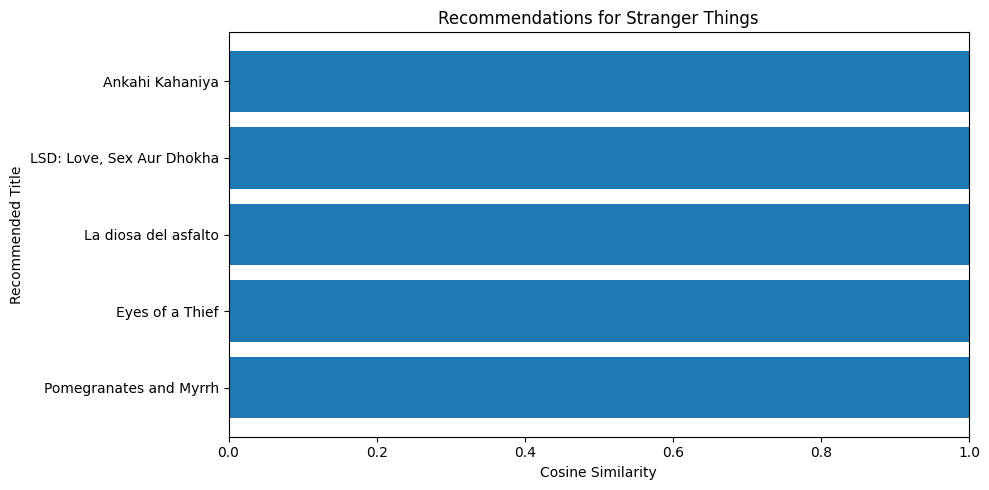

In [10]:
import matplotlib.pyplot as plt

# Generate recommendations ONCE
results = recommend("Sankofa", 5)   #modify the title u wanna get recommendation

if results is not None and not results.empty:

    # Plot similarity scores
    plt.figure(figsize=(10, 5))

    plt.barh(results["Title"], results["Similarity"])

    plt.xlabel("Cosine Similarity")
    plt.ylabel("Recommended Title")
    plt.title("Recommendations for Stranger Things")

    plt.xlim(0, 1)
    plt.gca().invert_yaxis()

    plt.tight_layout()
    plt.show()